# 10.6 — The Plotting Accessor and Its Bound

**Chapter 10, section 7.2** — "Plotting Directly from a PySpark DataFrame", and the row limit
introduced in §5.1. The worked answer to **Exercise 8**.

**The question this notebook answers:** `df.plot` cannot send a billion rows to a browser, so it sends
some bounded number instead. *Which* rows, and does the picture tell you?

§7.2 says the accessor *"does not remove the analyst's responsibility to prepare the data
appropriately"*, and Exercise 8 is the case where that responsibility is skipped: a bar plot called
straight on an unaggregated table, which produces a chart, gets put in a report, and means nothing.

**A note on output.** The accessor returns a Plotly figure, and rendering one embeds a JavaScript
bundle into this notebook. So the cells below **read the data out of the returned figure** instead of
displaying it. That is also the more useful thing to look at: the whole question here is which rows
reached the figure.

In [1]:
# --- CS-777 session setup ------------------------------------------------
import os, tempfile, inspect
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (StructType, StructField, StringType,
                               IntegerType, DoubleType, TimestampType)
import matplotlib.pyplot as plt

DATA = os.environ.get("CS777_DATA", "../data")
SCRATCH = os.environ.get("CS777_SCRATCH", os.path.join(tempfile.gettempdir(), "cs777"))

spark = (SparkSession.builder
         .appName("CS777-10.6")
         .master("local[*]")
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.warehouse.dir", os.path.join(SCRATCH, "warehouse"))
         .config("spark.driver.memory", "3g")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

MAX_ROWS_DEFAULT = spark.conf.get("spark.sql.pyspark.plotting.max_rows")
print(f"pyspark {spark.version}")
print(f"spark.sql.pyspark.plotting.max_rows = {MAX_ROWS_DEFAULT}   (the default)")

pyspark 4.2.0
spark.sql.pyspark.plotting.max_rows = 1000   (the default)


---

## 1. The documentation example, in both of its forms

This is the listing the chapter prints at §7.2, run as written.

In [2]:
data = [("A", 10, 1.5), ("B", 30, 2.5), ("C", 20, 3.5)]
df = spark.createDataFrame(data, ["category", "int_val", "float_val"])

fig_method = df.plot.line(x="category", y=["int_val", "float_val"])
fig_kind   = df.plot(kind="line", x="category", y=["int_val", "float_val"])

print(f"return type: {type(fig_method).__module__}.{type(fig_method).__name__}")
assert all(list(a.y) == list(b.y) for a, b in zip(fig_method.data, fig_kind.data))
print("the two documented forms produce identical traces -- asserted\n")
for tr in fig_method.data:
    print(f"  trace {tr.name:<10} x={list(tr.x)}  y={[float(v) for v in tr.y]}")

kinds = sorted(k for k in dir(df.plot)
               if not k.startswith("_") and k not in ("data", "plot_data_map"))
print(f"\nsupported kinds ({len(kinds)}): {', '.join(kinds)}")

return type: plotly.graph_objs._figure.Figure
the two documented forms produce identical traces -- asserted

  trace int_val    x=['A', 'B', 'C']  y=[10.0, 30.0, 20.0]
  trace float_val  x=['A', 'B', 'C']  y=[1.5, 2.5, 3.5]

supported kinds (9): area, bar, barh, box, hist, kde, line, pie, scatter


The chapter's two claims about the accessor both hold: it returns a **Plotly figure**, and it supports
the nine kinds §7.2 lists — `area`, `bar`, `barh`, `line`, `pie`, `scatter`, `box`, `kde`, `hist`.

---

## 2. The bound is one setting and three different behaviours

§5.1: *"For top-n visualizations such as bar and pie charts, the plotting system uses a bounded number
of rows, while plot types based on individual observations can use random sampling."*

One configuration value, `spark.sql.pyspark.plotting.max_rows`, governs all of it — but which
*strategy* a kind uses is fixed in PySpark, not chosen by the caller. The map is in the source, so it
can be read rather than guessed.

In [3]:
from pyspark.sql.plot import core as plot_core

strategy = {}
for kind, fn in plot_core.PySparkPlotAccessor.plot_data_map.items():
    owner = getattr(fn, "__self__", None)
    strategy[kind] = type(owner).__name__ if owner else fn.__name__

for kind in sorted(strategy):
    print(f"  {kind:<10} {strategy[kind]}")
print("\n  box / hist / kde are not in that map: they have their own classes, and")
print("  they compute their statistics IN THE ENGINE. Section 5 comes back to them.")

  area       PySparkSampledPlotBase
  bar        PySparkTopNPlotBase
  barh       PySparkTopNPlotBase
  line       PySparkSampledPlotBase
  pie        PySparkTopNPlotBase
  scatter    PySparkSampledPlotBase

  box / hist / kde are not in that map: they have their own classes, and
  they compute their statistics IN THE ENGINE. Section 5 comes back to them.


In [4]:
# The two strategies, side by side, on 100 rows with the bound set to 5.
spark.conf.set("spark.sql.pyspark.plotting.max_rows", 5)
hundred = spark.range(100).selectExpr("cast(id as string) as k", "id % 7 as v")

for kind in ["bar", "scatter", "line"]:
    fig = getattr(hundred.plot, kind)(x="k", y="v")
    got = list(fig.data[0].x)
    print(f"  {kind:<8} {strategy[kind]:<24} {len(got)} of 100 rows -> k = {got}")

spark.conf.set("spark.sql.pyspark.plotting.max_rows", MAX_ROWS_DEFAULT)

  bar      PySparkTopNPlotBase      5 of 100 rows -> k = ['0', '1', '2', '3', '4']
  scatter  PySparkSampledPlotBase   5 of 100 rows -> k = ['27', '36', '48', '60', '72']


  line     PySparkSampledPlotBase   5 of 100 rows -> k = ['13', '42', '64', '72', '84']


`bar` took rows 0 through 4. `scatter` and `line` took five rows chosen at random. Both are "a bounded
number of rows", and they are not the same thing at all.

### "Top n" is a `limit`, and nothing tells the caller

The method behind `bar`, `barh` and `pie` is named `get_top_n`, which reads like a promise to keep the
largest values. It is not one.

In [5]:
print(inspect.getsource(plot_core.PySparkTopNPlotBase.get_top_n))

    def get_top_n(self, sdf: "DataFrame") -> "pd.DataFrame":
        max_rows = int(
            sdf._session.conf.get("spark.sql.pyspark.plotting.max_rows")  # type: ignore[arg-type]
        )
        pdf = sdf.limit(max_rows + 1).toPandas()

        self.partial = False
        if len(pdf) > max_rows:
            self.partial = True
            pdf = pdf.iloc[:max_rows]

        return pdf



`sdf.limit(max_rows + 1)` — the **first** rows the scan happens to return, in whatever order the
partitions produce them. No `orderBy`, so "top" means *first*, not *largest*.

Two consequences, and the second is the one Exercise 8 turns on:

1. The same call on the same data can produce a **different chart** if the rows arrive in a different
   order — after a repartition, a different file layout, or a different number of cores.
2. `self.partial = True` is set when truncation happens, and **nothing ever reads it**. There is no
   warning, no annotation on the figure, no note in the title. A truncated chart is indistinguishable
   from a complete one.

In [6]:
# 1. Order decides the content, so the same query gives two different "top 5" charts.
spark.conf.set("spark.sql.pyspark.plotting.max_rows", 5)
as_written = hundred.plot.bar(x="k", y="v")
sorted_desc = hundred.orderBy(F.desc("v"), "k").plot.bar(x="k", y="v")
print(f"unsorted   -> k = {list(as_written.data[0].x)}  "
      f"v = {[int(v) for v in as_written.data[0].y]}")
print(f"sorted desc-> k = {list(sorted_desc.data[0].x)}  "
      f"v = {[int(v) for v in sorted_desc.data[0].y]}")
print("Same data, same call, different bars. If a 'top 5' is wanted, it has to be asked for.\n")

# 2. Truncation is recorded and never surfaced.
base = plot_core.PySparkTopNPlotBase()
base.get_top_n(hundred)
print(f"after truncating 100 rows to 5, PySparkTopNPlotBase.partial = {base.partial}")
print("Searching the plotting package for any use of that flag:")
import pathlib as _p
hits = [f"{f.name}:{i}" for f in _p.Path(plot_core.__file__).parent.glob("*.py")
        for i, line in enumerate(f.read_text().splitlines(), 1)
        if "partial" in line]
print(f"  {hits}")
print("  -- the only mentions are where it is SET. Nothing reads it, so the figure")
print("     carries no sign that two thirds of the data never arrived.")
spark.conf.set("spark.sql.pyspark.plotting.max_rows", MAX_ROWS_DEFAULT)

unsorted   -> k = ['0', '1', '2', '3', '4']  v = [0, 1, 2, 3, 4]
sorted desc-> k = ['13', '20', '27', '34', '41']  v = [6, 6, 6, 6, 6]
Same data, same call, different bars. If a 'top 5' is wanted, it has to be asked for.

after truncating 100 rows to 5, PySparkTopNPlotBase.partial = True
Searching the plotting package for any use of that flag:
  ['core.py:41', 'core.py:43']
  -- the only mentions are where it is SET. Nothing reads it, so the figure
     carries no sign that two thirds of the data never arrived.


---

## 3. Exercise 8 — auditing the colleague's chart

> A colleague executes the following command on the complete taxi DataFrame, observes that a chart is
> successfully produced, and includes it in a report.
>
> ```python
> df.plot.bar(x="vendor", y="fare_amount")
> ```

This extract has no `vendor` column; the categorical column of the same shape is `payment_type`, with
five values. Everything else about the situation is preserved — a bar plot, called on the complete
unaggregated table, that succeeds.

In [7]:
taxi_schema = StructType([
    StructField("medallion", StringType()), StructField("hack_license", StringType()),
    StructField("pickup_datetime", TimestampType()), StructField("dropoff_datetime", TimestampType()),
    StructField("trip_time", IntegerType()), StructField("trip_distance", DoubleType()),
    StructField("pickup_longitude", DoubleType()), StructField("pickup_latitude", DoubleType()),
    StructField("dropoff_longitude", DoubleType()), StructField("dropoff_latitude", DoubleType()),
    StructField("payment_type", StringType()), StructField("fare_amount", DoubleType()),
    StructField("surcharge", DoubleType()), StructField("mta_tax", DoubleType()),
    StructField("tip_amount", DoubleType()), StructField("tolls_amount", DoubleType()),
    StructField("total_amount", DoubleType()),
])

taxi = (spark.read.schema(taxi_schema).option("header", "false")
        .csv(os.path.join(DATA, "taxi-data-sorted-small.csv.bz2"))
        .select("payment_type", "fare_amount")
        .filter((F.col("fare_amount") > 0) & (F.col("fare_amount") < 500))
        .cache())

TOTAL = taxi.count()
print(f"the complete table: {TOTAL:,} trips, {taxi.select('payment_type').distinct().count()} payment types")

the complete table: 1,999,999 trips, 5 payment types


In [8]:
# The colleague's line, exactly as written.
chart = taxi.plot.bar(x="payment_type", y="fare_amount")

xs, ys = list(chart.data[0].x), list(chart.data[0].y)
print(f"bars drawn:            {len(xs):,}")
print(f"rows in the table:     {TOTAL:,}")
print(f"fraction represented:  {len(xs) / TOTAL:.4%}")
print(f"\nfirst 8 bars:  x = {xs[:8]}")
print(f"               y = {[float(v) for v in ys[:8]]}")

all_types = sorted(r["payment_type"] for r in
                   taxi.select("payment_type").distinct().collect())
drawn = sorted(set(xs))
print(f"\npayment types in the table:  {all_types}")
print(f"payment types in the chart:  {drawn}")
print(f"  -> {len(xs):,} bars share {len(drawn)} labels, and "
      f"{len(all_types) - len(drawn)} of the {len(all_types)} types never appear at all")

bars drawn:            1,000
rows in the table:     1,999,999
fraction represented:  0.0500%

first 8 bars:  x = ['CSH', 'CSH', 'CSH', 'CSH', 'CRD', 'CRD', 'CRD', 'CSH']
               y = [3.5, 27.0, 4.0, 4.0, 4.0, 2.5, 3.0, 2.5]



payment types in the table:  ['CRD', 'CSH', 'DIS', 'NOC', 'UNK']
payment types in the chart:  ['CRD', 'CSH', 'UNK']
  -> 1,000 bars share 3 labels, and 2 of the 5 types never appear at all


### What the chart represents, precisely

It is **one bar per row** for the first 1,000 rows of the table, in scan order — not one bar per
payment type. Each bar's height is that single trip's `fare_amount`. A thousand bars are drawn onto the
handful of x-positions those thousand rows happen to use, so the visible figure is a few dense stacks of
overlapping bars whose apparent height is whichever row was drawn last.

And the cell above reports something worse than overlap: the thousand rows contain only **three** of the
table's five payment types, so two categories are **missing from the chart entirely** — not small, not
zero-height, simply absent, with nothing to indicate they were ever there. This is 10.3's rare-category
result reappearing, except that here it is not even a random sample: the rows are the first few minutes
of one morning, so the categories that survive are the ones that happened to occur early.

Restated against the three reductions of §5.1: the colleague wanted an **aggregate** — a statistic per
group — and the accessor performed a **`limit`**, which is not one of the three reductions at all. It
is not even a sample: 10.3 established that a sample of the first 1,000 time-sorted rows is not a
sample of the table, because these rows are the first few minutes of one morning.

**Why this is worse than a chart that obviously fails.** A failure sends the analyst back to the code.
This chart:

* **succeeds**, so nothing prompts a second look;
* is **plausible** — the axis labels are the right column names and the fare values are real fares;
* carries **no indication of truncation**, because `partial` is never read;
* represents **0.05%** of the data, chosen by scan order, and
* would **change** if the file were repartitioned, making it irreproducible in a way that is invisible.

The report then contains a figure captioned as fares by payment type which is really a thousand
individual fares from one morning, and no reader can tell.

In [9]:
# What the colleague meant. The aggregate is the plot, so compute it first -- 5.1's rule.
by_type = (taxi.groupBy("payment_type")
           .agg(F.round(F.avg("fare_amount"), 2).alias("avg_fare"),
                F.count("*").alias("trips"))
           .orderBy(F.desc("trips")))

fixed = by_type.plot.bar(x="payment_type", y="avg_fare")
print(f"corrected chart: {len(fixed.data[0].x)} bars for "
      f"{taxi.select('payment_type').distinct().count()} payment types\n")
by_type.show()

covered = by_type.agg(F.sum("trips")).first()[0]
print(f"rows represented: {covered:,} of {TOTAL:,} = {covered / TOTAL:.0%}")
print("Reduction used: AGGREGATE -- one mark per group, computed over every row,")
print("and 5 rows cross the boundary instead of 1,000.")

corrected chart: 5 bars for 5 payment types

+------------+--------+-------+
|payment_type|avg_fare|  trips|
+------------+--------+-------+
|         CRD|   12.82|1011236|
|         CSH|   10.95| 987134|
|         UNK|   16.41|   1626|
|         DIS|    5.25|      2|
|         NOC|     2.5|      1|
+------------+--------+-------+



rows represented: 1,999,999 of 1,999,999 = 100%
Reduction used: AGGREGATE -- one mark per group, computed over every row,
and 5 rows cross the boundary instead of 1,000.


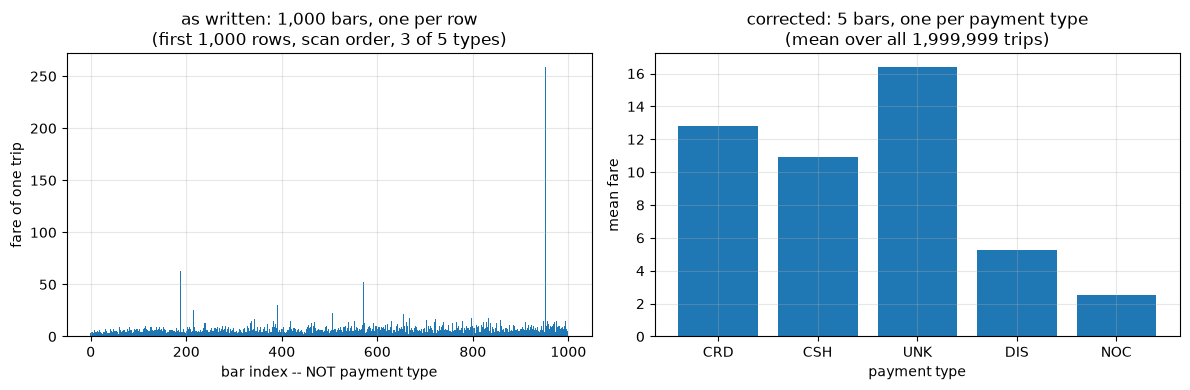

In [10]:
# The two charts side by side, drawn locally from the data each accessor call returned.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(len(xs)), ys, width=1.0)
axes[0].set_title(f"as written: {len(xs):,} bars, one per row\n"
                  f"(first 1,000 rows, scan order, {len(set(xs))} of 5 types)")
axes[0].set_xlabel("bar index -- NOT payment type"); axes[0].set_ylabel("fare of one trip")

fx, fy = list(fixed.data[0].x), list(fixed.data[0].y)
axes[1].bar(fx, fy)
axes[1].set_title(f"corrected: {len(fx)} bars, one per payment type\n(mean over all {TOTAL:,} trips)")
axes[1].set_xlabel("payment type"); axes[1].set_ylabel("mean fare")
for a in axes:
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

---

## 4. The kinds that do reduce properly

Not every kind truncates. `hist`, `box` and `kde` have their own implementations that compute their
statistics **in the engine** over every row — which is exactly the aggregate-and-summarize behaviour
§5.1 prescribes, done for you.

The check: the accessor's histogram against the one 10.5 built by hand with a `groupBy`.

In [11]:
hist_fig = taxi.plot.hist(column="fare_amount", bins=20)
acc_counts = list(hist_fig.data[0].y)

# The same thing by hand, over every row.
lo, hi = taxi.agg(F.min("fare_amount"), F.max("fare_amount")).first()
width = (hi - lo) / 20
manual = {r["b"]: r["n"] for r in
          taxi.withColumn("b", F.least(F.floor((F.col("fare_amount") - lo) / width),
                                       F.lit(19)))
              .groupBy("b").agg(F.count("*").alias("n")).collect()}
manual_counts = [manual.get(i, 0) for i in range(20)]

print(f"accessor hist bin counts sum to {sum(acc_counts):,}")
print(f"manual   hist bin counts sum to {sum(manual_counts):,}")
print(f"rows in the table              {TOTAL:,}")
assert sum(acc_counts) == TOTAL, "the accessor's histogram must cover every row"
print("\nThe accessor's histogram is computed over EVERY row -- asserted above. It is an")
print("aggregate, so there is nothing to truncate and no caveat to put in the caption.")
print(f"\nfirst 6 bins  accessor {acc_counts[:6]}")
print(f"              manual   {manual_counts[:6]}")

accessor hist bin counts sum to 1,999,999
manual   hist bin counts sum to 1,999,999
rows in the table              1,999,999

The accessor's histogram is computed over EVERY row -- asserted above. It is an
aggregate, so there is nothing to truncate and no caveat to put in the caption.

first 6 bins  accessor [np.int64(1847340), np.int64(100854), np.int64(49214), np.int64(1565), np.int64(545), np.int64(230)]
              manual   [1847340, 100854, 49214, 1565, 545, 230]


---

## What this measured

**`df.plot` is three behaviours behind one setting, and the caller does not choose which.** Read out of
PySpark's own dispatch map: `bar`, `barh` and `pie` take the first `max_rows` rows; `line`, `area` and
`scatter` take a random sample of them; `hist`, `box` and `kde` compute in the engine over everything.
The chapter's §5.1 sentence is correct and is the least alarming way to state it — a bar chart and a
line chart of the same too-large DataFrame are reduced by *different* methods.

**The method named `get_top_n` is a `limit`.** No `orderBy`, so "top" means whichever rows the scan
returned first. Section 2 shows the same call on the same data producing different bars once the frame
is sorted, which makes any such chart dependent on partitioning and therefore not reproducible.

**Truncation is recorded and never surfaced.** `partial` is set to `True` and the only occurrences of
the name in the plotting package are the two lines that assign it. There is no warning and no mark on
the figure, so a chart built from 0.05% of a table looks exactly like one built from all of it.

**Exercise 8's chart is 1,000 bars, one per row, from the first few minutes of one morning.** It draws
them onto the few x-positions those rows use, so it reads as a handful of bars whose heights are
whichever row was drawn last — and only **three** of the five payment types appear in it at all, the
other two vanishing without trace. The colleague wanted one bar per payment type; the accessor performed
a `limit`, which is not one of §5.1's three reductions. It is more dangerous than a visible failure
precisely because it succeeds, is plausible, and is silent.

**The corrected version is an aggregate, and it is smaller as well as right.** `groupBy` then `avg`
sends **5 rows** across the boundary instead of 1,000, and those 5 rows account for 100% of the trips
rather than 0.05%. That is §5.1's rule paying twice, which is why *"the data should first be aggregated
according to the quantity the bars are intended to represent and only then passed to the plotting
interface."*

**And the accessor is not a trap everywhere.** Its histogram covers every row — asserted against a
hand-built `groupBy` in section 4. The distinction worth carrying is not "convenience API bad" but
which kinds reduce and which truncate, because only the truncating ones need the analyst to do the
reduction first.